# 5 · Agentic RAG vs fixed-K (naive) RAG — benchmark comparison

Responds to the Editor (point 5) and Reviewer 1: does agentic retrieval actually beat a simpler fixed-K pipeline?

**Inputs**
- `03_benchmark_rag_results_newquestion/agentic_rag/*.json` — agentic answers with human `verification` scores (5 correct, 4 partially correct, 3 undefined, 2 missing, 1 wrong)
- `03_benchmark_rag_results_newquestion/naive/{child,parent}/k{5,10,20}/*.json` — fixed-K runs
- `03_benchmark_rag_results_newquestion/naive/naive_binary_labels.csv` — Yes/No labels for the naive free-text answers. **Fill `your_check`** with `yes` / `no` / `not_found` to correct a label; blank keeps the existing label.

**Gold labels (binary questions)** come from the verified agentic answers: score 5/4 → gold = agentic answer; score 1/2/3 (wrong, missing, undefined) → gold = the opposite. This matches Table S6, where missing or undefined answers count as errors. `not_found` is scored as "No".

**Outputs** (written to the `naive` folder): `rag_comparison_binary.csv`, `rag_comparison_by_question.csv`, `confidence_vs_accuracy_binary.csv`.

In [2]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import binomtest, fisher_exact, spearmanr

from config_loader import load_config

cfg         = load_config()
AGENTIC_DIR = Path(cfg['paths']['benchmark_result_folder'])
NAIVE_DIR   = AGENTIC_DIR.parent / 'naive'
LABELS_CSV  = NAIVE_DIR / 'naive_binary_labels.csv'
PLOT_OUTPUT_DIR     = Path(cfg['paths']['fig_folder'])

# Same questions as Table S6. Q11 and Q15 are scored as binary:
#   Q11 'regional/local' or 'both' = Yes (downscaled), 'global' only = No
#   Q15 'both' = Yes; 'direct' or 'indirect' only = No
BINARY  = [4, 5, 6, 7, 9, 11, 13, 14, 15]
QNAME   = {4: 'Pick-and-mix SSP/RCP', 5: 'Customised', 6: 'Co-produced', 7: 'Baseline',
           9: 'Acute damage', 11: 'Downscaled', 13: 'Justification', 14: 'Historic impacts',
           15: "Direct/indirect risk"}
CONFIGS = ['agentic'] + [f'{m}-k{k}' for m in ('child', 'parent') for k in (5, 10, 20)]
LEVELS  = ['high', 'medium', 'low']


def config_dir(config):
    if config == 'agentic':
        return AGENTIC_DIR
    mode, k = config.split('-')
    return NAIVE_DIR / mode / k


def explicit_yes_no(answer):
    """'yes' / 'no' / 'not_found' if the answer starts with one, else None (free text)"""
    words = re.sub(r'[^a-z_]', ' ', str(answer).lower()).split()
    return words[0] if words and words[0] in ('yes', 'no', 'not_found') else None


def binary_label(q_id, answer):
    """Yes/No/not_found for a binary question (Q11 and Q15 mapped from their categories)"""
    if q_id == 11:
        text = ' '.join(re.sub(r'[^a-z_/]', ' ', str(answer).lower()).split())
        if text.startswith(('both', 'regional', 'local')):
            return 'yes'
        if text.startswith('global') and not text.startswith('global and') and 'downscal' not in text[:60]:
            return 'no'
        if text.startswith('not_found'):
            return 'not_found'
        return None
    if q_id == 15:
        words = re.sub(r'[^a-z_]', ' ', str(answer).lower()).split()
        if words and words[0] == 'both':
            return 'yes'
        if words and words[0] in ('direct', 'indirect') and words[1:2] != ['and']:
            return 'no'
        if words and words[0] == 'not_found':
            return 'not_found'
        return None
    return explicit_yes_no(answer)

print('agentic:', AGENTIC_DIR)
print('naive  :', NAIVE_DIR)

agentic: C:\Users\QuyenN\OneDrive - ESNZ\Offline_work\2_GNS\19_LLM_ClimateRisk2026\4-Github2026_LLM\LLM_climaterisk_2026\03_benchmark_rag_results_newquestion\agentic_rag
naive  : C:\Users\QuyenN\OneDrive - ESNZ\Offline_work\2_GNS\19_LLM_ClimateRisk2026\4-Github2026_LLM\LLM_climaterisk_2026\03_benchmark_rag_results_newquestion\naive


## 1 · Load every answer

In [3]:
records = []
for config in CONFIGS:
    for path in sorted(config_dir(config).glob('*.json')):
        data   = json.load(open(path, encoding='utf-8'))
        tokens = sum(m.get('total_tokens', 0) for m in data.get('token_usage', {}).values())
        for a in data['answers']:
            records.append({'config': config, 'company': path.stem, 'q_id': int(a['q_id']),
                            'answer': a.get('answer'), 'confidence': str(a.get('confidence') or '').lower(),
                            'verification': a.get('verification'), 'tokens_doc': tokens})
answers = pd.DataFrame(records)
answers.groupby('config').agg(docs=('company', 'nunique'), answers=('q_id', 'size'))

,docs,answers
config,,
agentic,26,390
child-k10,26,390
child-k20,26,390
child-k5,26,390
parent-k10,26,390
parent-k20,26,390
parent-k5,26,390


## 2 · Gold labels from the verified agentic answers

In [4]:
def gold_from(row):
    pred, score = binary_label(row['q_id'], row['answer']), row['verification']
    if pred is None or pd.isna(score):
        return None
    pred = 'no' if pred == 'not_found' else pred
    if score in (4, 5):
        return pred
    if score in (1, 2, 3):                        # wrong / missing / undefined: the opposite holds (as Table S6)
        return 'no' if pred == 'yes' else 'yes'
    return None

ag   = answers[(answers.config == 'agentic') & answers.q_id.isin(BINARY)]
gold = ag.assign(gold=ag.apply(gold_from, axis=1)).dropna(subset=['gold'])[['company', 'q_id', 'gold']]
print(f'{len(gold)} gold items; always-Yes baseline accuracy = {(gold.gold == "yes").mean():.3f}')
gold.groupby('q_id').gold.value_counts().unstack(fill_value=0)

234 gold items; always-Yes baseline accuracy = 0.782


gold,no,yes
q_id,,
4,8,18
5,3,23
6,12,14
7,21,5
9,0,26
11,3,23
13,3,23
14,0,26
15,1,25


## 3 · Yes/No labels for every setup

Explicit Yes/No/not_found answers are used as they are. Naive free-text answers take their label from `naive_binary_labels.csv`; a filled `your_check` overrides it. Any answer still without a label is dropped (count shown below — should be 0).

In [5]:
labels = pd.read_csv(LABELS_CSV, dtype={'your_check': str})
labels['final'] = labels['your_check'].str.strip().str.lower().where(
    labels['your_check'].notna() & (labels['your_check'].str.strip() != ''), labels['label'])
bad = labels.loc[~labels.final.isin(['yes', 'no', 'not_found']), ['config', 'company', 'q_id', 'your_check']]
assert bad.empty, f'Unrecognised your_check values:\n{bad}'
print('labels corrected by you:', int((labels.final != labels.label).sum()))
lookup = labels.set_index(['config', 'company', 'q_id'])[['final', 'certainty']]

binary = answers[answers.q_id.isin(BINARY)].copy()
binary['label'] = [binary_label(q, a) for q, a in zip(binary.q_id, binary.answer)]
binary['certainty'] = 'high'
need = binary.label.isna() & (binary.config != 'agentic')
idx = pd.MultiIndex.from_frame(binary.loc[need, ['config', 'company', 'q_id']])
binary.loc[need, 'label'] = lookup['final'].reindex(idx).to_numpy()
binary.loc[need, 'certainty'] = lookup['certainty'].reindex(idx).to_numpy()

unlabelled = binary[binary.label.isna()]
print('unlabelled (dropped):', unlabelled.groupby('q_id').size().to_dict())
binary = binary.dropna(subset=['label']).merge(gold, on=['company', 'q_id'])
binary['pred']    = np.where(binary.label == 'yes', 'yes', 'no')
binary['correct'] = (binary.pred == binary.gold).astype(int)
binary.groupby('config').size()

labels corrected by you: 0
unlabelled (dropped): {}


config
agentic       234
child-k10     234
child-k20     234
child-k5      234
parent-k10    234
parent-k20    234
parent-k5     234
dtype: int64

## 4 · Accuracy, precision, recall, specificity

In [6]:
def metrics(df):
    tp = ((df.pred == 'yes') & (df.gold == 'yes')).sum(); fp = ((df.pred == 'yes') & (df.gold == 'no')).sum()
    tn = ((df.pred == 'no') & (df.gold == 'no')).sum();   fn = ((df.pred == 'no') & (df.gold == 'yes')).sum()
    div = lambda a, b: a / b if b else np.nan
    return pd.Series({'n': len(df), 'accuracy': div(tp + tn, len(df)), 'precision': div(tp, tp + fp),
                      'recall': div(tp, tp + fn), 'specificity': div(tn, tn + fp)})

summary = binary.groupby('config').apply(metrics, include_groups=False).reindex(CONFIGS)
summary['accuracy_high_certainty_only'] = (binary[binary.certainty == 'high']
                                           .groupby('config').correct.mean().reindex(CONFIGS))
summary['low_certainty_labels'] = binary.groupby('config').certainty.apply(lambda s: (s == 'low').sum())
summary['not_found_binary'] = binary.groupby('config').label.apply(lambda s: s.eq('not_found').mean())
summary['not_found_rate_all_q'] = answers.groupby('config').answer.apply(
    lambda s: s.map(explicit_yes_no).eq('not_found').mean())
summary['tokens_per_doc'] = answers.groupby('config').apply(
    lambda d: d.drop_duplicates('company').tokens_doc.mean(), include_groups=False)
summary.to_csv(PLOT_OUTPUT_DIR / 'Table_rag_comparison_binary.csv')
summary.round(3)

,n,accuracy,precision,recall,specificity,accuracy_high_certainty_only,low_certainty_labels,not_found_binary,not_found_rate_all_q,tokens_per_doc
config,,,,,,,,,,
agentic,234.0,0.910,0.935,0.951,0.765,0.910,0,0.004,0.008,1043426.808
child-k5,234.0,0.662,0.919,0.623,0.804,0.698,75,0.269,0.203,31617.808
child-k10,234.0,0.714,0.920,0.694,0.784,0.727,84,0.188,0.133,40570.885
child-k20,234.0,0.748,0.919,0.743,0.765,0.812,69,0.137,0.082,58107.115
parent-k5,234.0,0.735,0.923,0.721,0.784,0.810,76,0.158,0.103,59479.462
parent-k10,234.0,0.782,0.934,0.776,0.804,0.850,74,0.124,0.064,93857.962
parent-k20,234.0,0.816,0.917,0.842,0.725,0.924,76,0.060,0.026,160746.308


In [7]:
by_q = binary.pivot_table(index='q_id', columns='config', values='correct', aggfunc='mean')[CONFIGS]
by_q.index = [f'Q{q} {QNAME[q]}' for q in by_q.index]
by_q.to_csv(PLOT_OUTPUT_DIR / 'Table_rag_comparison_by_question.csv')
by_q.round(2)

config,agentic,child-k5,child-k10,child-k20,parent-k5,parent-k10,parent-k20
Q4 Pick-and-mix SSP/RCP,0.77,0.69,0.69,0.77,0.69,0.69,0.77
Q5 Customised,0.96,0.81,0.92,0.92,0.92,0.96,0.96
Q6 Co-produced,0.85,0.73,0.62,0.69,0.69,0.73,0.65
Q7 Baseline,0.73,0.77,0.77,0.77,0.77,0.81,0.73
Q9 Acute damage,0.96,0.96,0.96,0.92,0.96,1.00,1.00
Q11 Downscaled,0.96,0.58,0.69,0.73,0.58,0.65,0.73
Q13 Justification,1.00,0.85,0.88,0.88,0.92,0.96,0.92
Q14 Historic impacts,1.00,0.12,0.19,0.31,0.27,0.38,0.73
Q15 Direct/indirect risk,0.96,0.46,0.69,0.73,0.81,0.85,0.85


## 5 · Paired test: agentic vs each fixed-K setup (exact McNemar)

In [8]:
wide = binary.pivot_table(index=['company', 'q_id'], columns='config', values='correct')
rows = []
for config in CONFIGS[1:]:
    pair = wide[['agentic', config]].dropna()
    b = int(((pair.agentic == 1) & (pair[config] == 0)).sum())   # only agentic correct
    c = int(((pair.agentic == 0) & (pair[config] == 1)).sum())   # only fixed-K correct
    p = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
    rows.append({'config': config, 'n_paired': len(pair), 'only_agentic_correct': b,
                 'only_fixedK_correct': c, 'mcnemar_exact_p': p})
mcnemar = pd.DataFrame(rows).set_index('config')
mcnemar.round(3)

,n_paired,only_agentic_correct,only_fixedK_correct,mcnemar_exact_p
config,,,,
child-k5,234,68,10,0.000
child-k10,234,55,9,0.000
child-k20,234,46,8,0.000
parent-k5,234,53,12,0.000
parent-k10,234,41,11,0.000
parent-k20,234,31,9,0.001


In [9]:
# Table S7a: agentic vs fixed-K linear RAG on the binary questions, formatted as in the manuscript
CONFIG_LABEL = {'agentic': 'Agentic RAG (used in the main analysis)',
                'child-k5': 'Linear RAG, child chunk, k=5', 'child-k10': 'Linear RAG, child chunk, k=10',
                'child-k20': 'Linear RAG, child chunk, k=20', 'parent-k5': 'Linear RAG, parent chunk, k=5',
                'parent-k10': 'Linear RAG, parent chunk, k=10', 'parent-k20': 'Linear RAG, parent chunk, k=20'}
pct = lambda x: f'{100 * x:.1f}%'
pval = lambda p: '' if pd.isna(p) else ('<0.001' if p < 0.001 else f'{p:.3f}')
table_s7a = pd.DataFrame({
    'Accuracy':          summary.accuracy.map(pct),
    'Precision':         summary.precision.map(pct),
    'Recall':            summary.recall.map(pct),
    'Specificity':       summary.specificity.map(pct),
    'Used tokens':       summary.tokens_per_doc.round().astype(int).map('{:,}'.format),
    'P-value':           mcnemar.mcnemar_exact_p.reindex(CONFIGS).map(pval),
    'Not found answers': summary.not_found_binary.map(pct),
}).rename(index=CONFIG_LABEL)
table_s7a.index.name = 'RAG configuration'
table_s7a.to_csv(PLOT_OUTPUT_DIR / 'Table_S7a_rag_comparison.csv', encoding='utf-8-sig')
print(f'n = {int(summary.n.iloc[0])} binary answers per configuration')
table_s7a

n = 234 binary answers per configuration


,Accuracy,Precision,Recall,Specificity,Used tokens,P-value,Not found answers
RAG configuration,,,,,,,
Agentic RAG (used in the main analysis),91.0%,93.5%,95.1%,76.5%,"1,043,427",,0.4%
"Linear RAG, child chunk, k=5",66.2%,91.9%,62.3%,80.4%,"31,618",<0.001,26.9%
"Linear RAG, child chunk, k=10",71.4%,92.0%,69.4%,78.4%,"40,571",<0.001,18.8%
"Linear RAG, child chunk, k=20",74.8%,91.9%,74.3%,76.5%,"58,107",<0.001,13.7%
"Linear RAG, parent chunk, k=5",73.5%,92.3%,72.1%,78.4%,"59,479",<0.001,15.8%
"Linear RAG, parent chunk, k=10",78.2%,93.4%,77.6%,80.4%,"93,858",<0.001,12.4%
"Linear RAG, parent chunk, k=20",81.6%,91.7%,84.2%,72.5%,"160,746",<0.001,6.0%


## 8 · Agentic search log (benchmark run)

`retrieval_trace` in each agentic benchmark file records every search the agent made and the question it was for. How often does the agent search more than once, and does that relate to confidence and correctness?

In [10]:
from scipy.stats import mannwhitneyu

trace_rows = []
for path in sorted(AGENTIC_DIR.glob('*.json')):
    data = json.load(open(path, encoding='utf-8'))
    for step, t in enumerate(data.get('retrieval_trace', []), start=1):
        if t.get('q_id') is not None:
            trace_rows.append({'company': path.stem, 'step': step, 'q_id': int(t['q_id']),
                               'tool': t.get('tool'), 'query': t.get('query'), 'k': t.get('k'),
                               'n_results': t.get('n_results')})
trace = pd.DataFrame(trace_rows)
# two tools: search_knowledge_base (a search) and get_page (opening a page in full)
is_search = trace.tool == 'search_knowledge_base'
n_search = trace[is_search].groupby(['company', 'q_id']).size().rename('searches')
n_page   = trace[~is_search].groupby(['company', 'q_id']).size().rename('page_lookups')

ag_all = answers[answers.config == 'agentic'].set_index(['company', 'q_id'])
ag_all = ag_all.join(n_search).join(n_page).fillna({'searches': 0, 'page_lookups': 0})
ag_all[['searches', 'page_lookups']] = ag_all[['searches', 'page_lookups']].astype(int)

print(f"retrieval actions logged: {len(trace)} = {is_search.sum()} searches + {(~is_search).sum()} page look-ups, "
      f"for {len(ag_all)} answers (mean {ag_all.searches.mean():.2f} searches per question)")
print('answers by number of searches:', ag_all.searches.value_counts().sort_index().to_dict())
(ag_all.groupby('q_id').searches.agg(mean='mean', share_more_than_one=lambda s: (s > 1).mean())
 .rename(index=lambda q: f'Q{q}').round(2).T)

retrieval actions logged: 443 = 414 searches + 29 page look-ups, for 390 answers (mean 1.06 searches per question)
answers by number of searches: {0: 6, 1: 354, 2: 30}


q_id,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15
mean,1.0,1.0,1.0,1.04,1.00,1.0,1.12,1.12,1.15,1.23,1.04,0.92,1.12,1.15,1.04
share_more_than_one,0.0,0.0,0.0,0.04,0.04,0.0,0.12,0.12,0.15,0.27,0.04,0.08,0.12,0.15,0.04


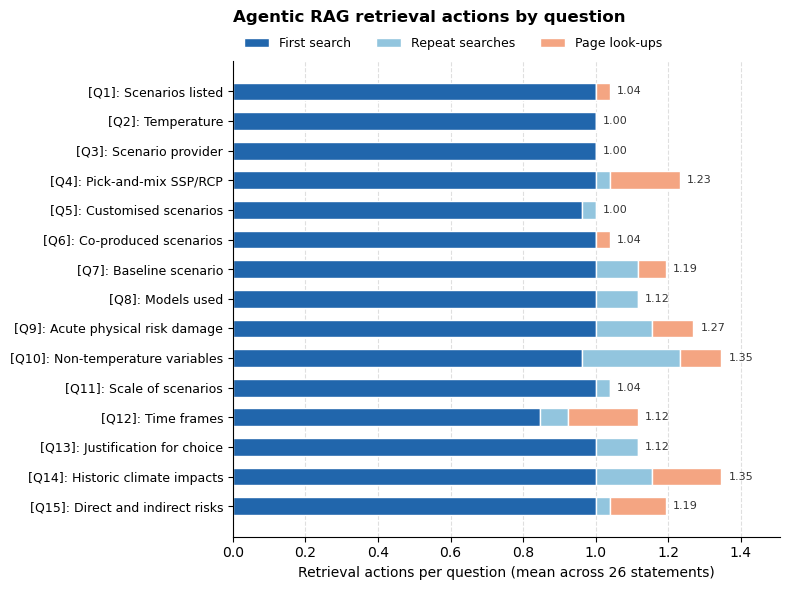

In [11]:
# Figure: retrieval actions per question (agentic RAG, 26 benchmark statements)
import matplotlib.pyplot as plt

act = ag_all.reset_index()
per_q = pd.DataFrame({
    'First search':    act.searches.clip(upper=1),
    'Repeat searches': (act.searches - 1).clip(lower=0),
    'Page look-ups':   act.page_lookups,
    'q_id':            act.q_id,
}).groupby('q_id').mean()

QUESTION_LABEL = {1: 'Scenarios listed', 2: 'Temperature', 3: 'Scenario provider', 4: 'Pick-and-mix SSP/RCP',
                  5: 'Customised scenarios', 6: 'Co-produced scenarios', 7: 'Baseline scenario',
                  8: 'Models used', 9: 'Acute physical risk damage', 10: 'Non-temperature variables',
                  11: 'Scale of scenarios', 12: 'Time frames', 13: 'Justification for choice',
                  14: 'Historic climate impacts', 15: 'Direct and indirect risks'}
labels = [f'[Q{q}]: {QUESTION_LABEL[q]}' for q in per_q.index]
SEGMENT_COLORS = {'First search': '#2166AC', 'Repeat searches': '#92C5DE', 'Page look-ups': '#F4A582'}

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(per_q))
left = np.zeros(len(per_q))
for seg, color in SEGMENT_COLORS.items():
    ax.barh(y, per_q[seg], left=left, height=0.6, color=color, edgecolor='white', linewidth=1, label=seg)
    left += per_q[seg].to_numpy()
for yi, total in zip(y, left):
    ax.text(total + 0.02, yi, f'{total:.2f}', va='center', fontsize=8, color='#333333')

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()                                   # Q1 at the top = order asked in the session
ax.set_xlabel('Retrieval actions per question (mean across 26 statements)')
ax.set_xlim(0, max(left) * 1.12)
ax.xaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9)
ax.set_title('Agentic RAG retrieval actions by question', fontsize=12, fontweight='bold', loc='left', pad=28)
plt.tight_layout()
plt.savefig(PLOT_OUTPUT_DIR / 'FigS_agentic_retrieval_actions.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


In [12]:
# Exact search terms for selected questions: first-search queries, and every statement with
# more than one retrieval action (searches and page look-ups in session order)
EXAMPLE_QUESTIONS = [4, 7, 6,8]

def short_name(company):
    for old, new in (('_LIMITED', ''), ('_GROUP', ''), ('_NEW_ZEALAND', '_NZ'),
                     ('_CORPORATION', ''), ('_HOLDINGS', '')):
        company = company.replace(old, new)
    return company

ordered = trace.sort_values(['company', 'step'])
searches_only = ordered[ordered.tool == 'search_knowledge_base']

# (a) the query used for the first search, with how many statements used it
first_queries = (searches_only.groupby(['company', 'q_id']).head(1)
                 .groupby(['q_id', 'query']).size().rename('statements').reset_index()
                 .sort_values(['q_id', 'statements'], ascending=[True, False]))

# (b) statements where the question needed more than one retrieval action
def describe(row):
    return f's{row.step}: [page look-up]' if row.tool == 'get_page' else f's{row.step}: {row.query}'

sequences = (ordered.groupby(['q_id', 'company']).filter(lambda g: len(g) > 1)
             .assign(action=lambda d: d.apply(describe, axis=1))
             .groupby(['q_id', 'company']).action.agg(' → '.join).reset_index()
             .rename(columns={'action': 'retrieval_sequence'}))
sequences['company'] = sequences.company.map(short_name)

with pd.ExcelWriter(PLOT_OUTPUT_DIR / 'Table_agentic_search_examples.xlsx') as xl:
    first_queries.to_excel(xl, sheet_name='first_search_queries', index=False)
    sequences.to_excel(xl, sheet_name='multi_action_sequences', index=False)

with pd.option_context('display.max_colwidth', 160, 'display.max_rows', 200):
    for q in EXAMPLE_QUESTIONS:
        n_s = (searches_only.q_id == q).sum()
        n_p = ((ordered.q_id == q) & (ordered.tool == 'get_page')).sum()
        print(f'\nQ{q}: {n_s} searches ({searches_only[searches_only.q_id == q]["query"].nunique()} distinct), '
              f'{n_p} page look-ups')
        display(first_queries[first_queries.q_id == q].drop(columns='q_id').reset_index(drop=True))
        display(sequences[sequences.q_id == q].drop(columns='q_id').reset_index(drop=True))


Q4: 27 searches (10 distinct), 5 page look-ups


,query,statements
0,SSP RCP combination mixing scenario families,12
1,SSP RCP combination scenario families mixing,3
2,SSP RCP scenario combination mixing families,3
3,SSP RCP scenario family combination,2
4,SSP RCP scenario family combination mixing,2
5,SSP RCP combination mixing scenario families Representative Concentration Pathway,1
6,SSP RCP representative concentration pathway shared socioeconomic pathway,1
7,SSP RCP scenario family representative concentration pathway shared socioeconomic,1
8,SSP RCP scenario identifiers combination,1


,company,retrieval_sequence
0,AA_INSURANCE_2025,s5: SSP RCP combination mixing scenario families → s17: RCP representative concentration pathway scenario
1,BANK_OF_NZ_2024,s4: SSP RCP combination mixing scenario families → s18: [page look-up]
2,CHRISTCHURCH_INTERNATIONAL_AIRPORT_2025,s4: SSP RCP combination mixing scenario families → s18: [page look-up] → s19: [page look-up]
3,LIVESTOCK_IMPROVEMENT_2025,s5: SSP RCP combination mixing scenario families → s17: [page look-up]
4,SUMMERSET_2024,s4: SSP RCP combination mixing scenario families → s18: [page look-up]



Q7: 29 searches (12 distinct), 2 page look-ups


,query,statements
0,baseline reference scenario comparison,9
1,baseline reference scenario business as usual comparison,5
2,baseline reference scenario comparison business as usual,3
3,baseline reference scenario comparison current policies,3
4,baseline reference scenario current policies business as usual,2
5,baseline reference scenario business as usual compared against,1
6,baseline reference scenario compared against,1
7,baseline reference scenario current policies comparison,1
8,baseline reference scenario current warming 1.1 degrees,1


,company,retrieval_sequence
0,FISHER__PAYKEL_HEALTHCARE_2025,s7: baseline reference scenario comparison current policies → s16: baseline scenario current policies no additional policy reference
1,FONTERRA_CO-OPERATIVE_2024,s13: [page look-up] → s14: baseline reference scenario business as usual compared against
2,MANAWA_ENERGY_2025,s8: baseline reference scenario current policies business as usual → s16: current policies reference case baseline scenario comparison
3,OCEANIA_HEALTHCARE_2025,s8: baseline reference scenario current policies comparison → s16: [page look-up]
4,RABOBANK_NZ_2023,s7: baseline reference scenario comparison → s16: current policies baseline no policy reference scenario comparison


... (2 outputs left out)

,company,retrieval_sequence
0,BANK_OF_NZ_2024,s6: participatory co-create co-design stakeholder input collaborative scenario development → s19: [page look-up]



Q8: 29 searches (17 distinct), 0 page look-ups


,query,statements
0,climate model integrated assessment model IAM CLIMADA REMIND MESSAGE GCAM macroeconomic model,5
1,climate model integrated assessment model IAM macroeconomic model CLIMADA REMIND MESSAGE,5
2,climate model integrated assessment model IAM macroeconomic model CLIMADA REMIND,3
3,climate model integrated assessment model IAM CLIMADA REMIND MESSAGE GCAM NiGEM,2
4,climate models integrated assessment models IAM macroeconomic models CLIMADA REMIND,2
5,climate model integrated assessment model GCAM REMIND MESSAGE NiGEM CLIMADA,1
6,climate model integrated assessment model IAM CLIMADA REMIND MESSAGE GCAM NiGEM macroeconomic model,1
7,climate model integrated assessment model IAM macroeconomic model GCAM REMIND,1
8,climate model integrated assessment model macroeconomic model CLIMADA REMIND MESSAGE GCAM,1
9,climate model integrated assessment model macroeconomic model CLIMADA REMIND NiGEM CGE,1


,company,retrieval_sequence
0,LIVESTOCK_IMPROVEMENT_2025,s9: climate model integrated assessment model IAM macroeconomic model CLIMADA REMIND MESSAGE → s18: ENZ model OverseerFM emanage model used scenario
1,TOWER_2024,s10: climate models integrated assessment models IAM macroeconomic models CLIMADA REMIND → s16: NGFS Climate Impact Explorer model tool used
2,WESTPAC_NZ_2024,s9: climate model integrated assessment model IAM CLIMADA REMIND MESSAGE GCAM macroeconomic model → s17: NIWA model coastal sensitivity index CSI flood mode...


In [13]:
by_conf = (ag_all[ag_all.confidence.isin(['high', 'medium'])]
           .groupby('confidence').searches
           .agg(n='size', mean_searches='mean', share_more_than_one=lambda s: (s > 1).mean()))
p_conf = mannwhitneyu(ag_all.loc[ag_all.confidence == 'high', 'searches'],
                      ag_all.loc[ag_all.confidence == 'medium', 'searches']).pvalue
print(f'high vs medium confidence, number of searches: Mann-Whitney p = {p_conf:.4f}')
display(by_conf.round(3))

ver_s = ag_all[ag_all.verification.notna()].copy()
ver_s['search_group'] = np.where(ver_s.searches > 1, 'more than one search', 'one search or none')
(ver_s.groupby('search_group').verification
 .agg(n='size', fully_correct=lambda s: (s == 5).mean(),
      correct_or_partial=lambda s: s.isin([4, 5]).mean(), wrong=lambda s: (s == 1).mean())
 .round(3))

high vs medium confidence, number of searches: Mann-Whitney p = 0.0012


,n,mean_searches,share_more_than_one
confidence,,,
high,334,1.042,0.060
medium,55,1.182,0.182


,n,fully_correct,correct_or_partial,wrong
search_group,,,,
more than one search,30,0.700,0.933,0.067
one search or none,360,0.853,0.928,0.050


## 9 · Open-ended questions (Q1, Q2, Q3, Q8, Q10, Q12)

Each answer was scored on the 5-tier scale (5 correct, 4 partially correct, 3 missing, 2 undefined, 1 wrong) against the expert's own extraction (`ani_notes`) by an LLM scorer that saw only an opaque id, the question, the reference and the answer — not the pipeline or the human score. Agentic and naive answers for the same question were scored together in one shuffled batch, so all pipelines are judged identically.

`naive_open_ended_scores.csv` holds every score; put 1–5 in `your_check` to override one. The main measure is **correct or partially correct (4–5)**, where the scorer agrees with the expert's own agentic scores in ~94% of cases; it is stricter than the expert on 5 vs 4.

In [14]:
OPEN_QS = [1, 2, 3, 8, 10, 12]
OPEN_CSV = NAIVE_DIR / 'naive_open_ended_scores.csv'

open_s = pd.read_csv(OPEN_CSV, dtype={'your_check': str})
override = pd.to_numeric(open_s.your_check, errors='coerce')
bad = open_s.your_check.notna() & open_s.your_check.str.strip().ne('') & ~override.isin([1, 2, 3, 4, 5])
assert not bad.any(), f'your_check must be 1-5:\n{open_s.loc[bad, ["config", "company", "q_id", "your_check"]]}'
open_s['final'] = override.fillna(open_s.score).astype(int)
open_s['ok'] = open_s.final.isin([4, 5]).astype(int)
print('scores overridden by you:', int(override.notna().sum()))

# scorer vs the expert's own scores on agentic answers
from sklearn.metrics import cohen_kappa_score
ag_open = open_s[open_s.config == 'agentic']
hum = ag_open.human_score.astype(int)
print(f"scorer vs expert on agentic answers (n={len(ag_open)}): exact {np.mean(hum == ag_open.final):.1%}, "
      f"correct-or-partial agreement {np.mean((hum >= 4) == (ag_open.final >= 4)):.1%}, "
      f"kappa {cohen_kappa_score(hum >= 4, ag_open.final >= 4):.2f}")

# compare pipelines on items with an expert-note reference (available for every pipeline)
common = open_s[open_s.ref_type == 'expert note']
open_summary = (common.groupby('config')
                .agg(n=('final', 'size'), correct_or_partial=('ok', 'mean'),
                     fully_correct=('final', lambda x: (x == 5).mean()),
                     missing=('final', lambda x: (x == 3).mean()), mean_score=('final', 'mean'))
                .reindex(CONFIGS))
wide_o = common.pivot_table(index=['company', 'q_id'], columns='config', values='ok')
p_open = {}
for config in CONFIGS[1:]:
    pair = wide_o[['agentic', config]].dropna()
    b = int(((pair.agentic == 1) & (pair[config] == 0)).sum()); c = int(((pair.agentic == 0) & (pair[config] == 1)).sum())
    p_open[config] = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
open_summary['mcnemar_p_vs_agentic'] = pd.Series(p_open)
open_summary['tokens_per_doc'] = summary['tokens_per_doc']
open_summary.to_csv(PLOT_OUTPUT_DIR / 'Table_rag_comparison_open_ended.csv')
open_summary.round(3)

scores overridden by you: 0
scorer vs expert on agentic answers (n=150): exact 60.0%, correct-or-partial agreement 94.0%, kappa 0.44


,n,correct_or_partial,fully_correct,missing,mean_score,mcnemar_p_vs_agentic,tokens_per_doc
config,,,,,,,
agentic,150,0.933,0.553,0.000,4.373,NaN,1043426.808
child-k5,150,0.673,0.287,0.227,3.780,0.000,31617.808
child-k10,150,0.767,0.347,0.120,3.933,0.000,40570.885
child-k20,150,0.820,0.380,0.067,4.020,0.000,58107.115
parent-k5,150,0.767,0.453,0.113,4.007,0.000,59479.462
parent-k10,150,0.840,0.547,0.027,4.180,0.001,93857.962
parent-k20,150,0.860,0.547,0.013,4.213,0.001,160746.308


In [15]:
OPEN_NAME = {1: 'Scenarios listed', 2: 'Temperature', 3: 'Scenario provider', 8: 'Models used',
             10: 'Non-temperature variables', 12: 'Time frames'}
open_by_q = common.pivot_table(index='q_id', columns='config', values='ok')[CONFIGS]
open_by_q.index = [f'[Q{q}]: {OPEN_NAME[q]}' for q in open_by_q.index]
open_by_q.to_csv(PLOT_OUTPUT_DIR / 'Table_rag_comparison_open_ended_by_question.csv')
print('share correct or partially correct (4-5):')
display(open_by_q.round(2))
full_by_q_open = common.assign(full=common.final.eq(5)).pivot_table(index='q_id', columns='config', values='full')[CONFIGS]
full_by_q_open.index = open_by_q.index
print('share fully correct (5):')
full_by_q_open.round(2)

share correct or partially correct (4-5):


config,agentic,child-k5,child-k10,child-k20,parent-k5,parent-k10,parent-k20
[Q1]: Scenarios listed,0.96,0.54,0.73,0.85,0.96,0.96,0.96
[Q2]: Temperature,1.00,0.96,1.00,1.00,0.92,1.00,1.00
[Q3]: Scenario provider,1.00,0.77,0.88,0.92,0.85,0.88,0.92
[Q8]: Models used,0.64,0.64,0.59,0.41,0.55,0.50,0.41
[Q10]: Non-temperature variables,0.96,0.46,0.50,0.73,0.50,0.73,0.81
[Q12]: Time frames,1.00,0.69,0.88,0.96,0.81,0.92,1.00


share fully correct (5):


config,agentic,child-k5,child-k10,child-k20,parent-k5,parent-k10,parent-k20
[Q1]: Scenarios listed,0.85,0.38,0.42,0.54,0.85,0.92,0.92
[Q2]: Temperature,0.79,0.33,0.58,0.71,0.62,0.83,0.83
[Q3]: Scenario provider,0.42,0.27,0.35,0.31,0.31,0.50,0.42
[Q8]: Models used,0.36,0.41,0.32,0.18,0.32,0.18,0.14
[Q10]: Non-temperature variables,0.08,0.00,0.00,0.00,0.00,0.04,0.08
[Q12]: Time frames,0.81,0.35,0.42,0.54,0.62,0.77,0.85


## 10 · Score-free comparison: standardised item matching and text similarity

An alternative to the 5-tier scores that needs no judgement. For the open-ended questions, every answer and the expert's own extraction (`ani_notes`) are **standardised** and split into items, then compared item by item:

- **Standardisation** reuses the maps behind Fig. 3, loaded directly from `3-rag_result.ipynb` (scenario, provider, model and variable maps, plus `List_of_mapped_models.csv`), and fixes spelling variants (e.g. `1.5oC` → `1.5°C`).
- **Items**: Q2 temperatures (match within ±0.1°C); Q12 years and durations; Q1/Q3/Q8/Q10 named items. Two named items match if they share a standardised name, one contains the other, or their strings are ≥75% similar.
- **Precision** = matched answer items / answer items; **recall** = matched reference items / reference items; **F1** their harmonic mean. Both empty (e.g. "no models named") = 1; one empty = 0.
- **TF-IDF cosine**: character 3–5-gram similarity of the answer and reference texts, computed twice: on the raw texts (no standardisation) and on the **standardised texts** (each item replaced by its canonical name(s) from the maps; °C values and years as tokens; both absent = 1). Validated against the expert's scores like F1.
- Expert notes such as "None (but … are mentioned)" are ambiguous and excluded.
- **Validation**: Spearman correlation between each measure and the expert's 5-tier scores on the agentic answers.
- **Comparison**: Wilcoxon signed-rank test, agentic vs each fixed-K setup, paired by statement and question.

In [16]:
# ==== CELL A: load the standardisation maps from 3-rag_result.ipynb ===========================
import ast
import difflib
import nbformat
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.stats import spearmanr, wilcoxon

# Reuse the exact maps behind Fig. 3: run the cell of 3-rag_result.ipynb that defines them
_rag_nb = nbformat.read(Path(cfg['paths']['scripts_dir']) / '3-rag_result.ipynb', as_version=4)
_map_cell = next(c.source for c in _rag_nb.cells if c.cell_type == 'code' and 'SCENARIO_MAP = {' in c.source)
exec(_map_cell)   # defines SCENARIO_MAP, MODEL_MAP, UNNAMED_MODEL_PATTERNS, TEMP_PATTERN, PROVIDER_MAP, VARIABLE_MAP, YEAR_PATTERN
_extra = pd.read_csv(Path(cfg['paths']['mapped_models']), encoding='latin1')
_extra = _extra[_extra.model.notna() & _extra.Name.notna() & (_extra.model != 'model')].drop_duplicates('Name')
MODEL_MAP.update({re.escape(n.strip().lower()): m.strip() for n, m in zip(_extra.Name, _extra.model)
                  if n.strip().lower() not in MODEL_MAP})
print(f'maps loaded: {len(SCENARIO_MAP)} scenario, {len(PROVIDER_MAP)} provider, '
      f'{len(MODEL_MAP)} model, {len(VARIABLE_MAP)} variable patterns')

maps loaded: 50 scenario, 17 provider, 240 model, 13 variable patterns


In [17]:
# ==== CELL B: standardise answers and references into item sets ===============================
ABSENT = re.compile(r"^\s*(not_found|not found|none\b|no\b|n/?a\b|not mentioned|not stated|not named|no specific)", re.I)
# expert notes like "None (but they are there, checked by F.)" are ambiguous: excluded, not treated as absent
AMBIGUOUS = re.compile(r"^\s*(none|no|not mentioned)\b.*\bbut\b", re.I)


def as_text(x):
    if isinstance(x, list):
        return '; '.join(map(str, x))
    s = str(x)
    if s.startswith('['):
        try:
            v = ast.literal_eval(s)
            if isinstance(v, list):
                return '; '.join(map(str, v))
        except (ValueError, SyntaxError):
            pass
    return s


def clean(text):
    """Standardise spelling before matching: degree signs, dashes, spaces, case."""
    s = as_text(text).replace(' ', ' ')
    s = re.sub(r'(\d)\s*(?:o|º|˚|deg(?:rees?)?)\s*c\b', r'\1°C', s, flags=re.I)   # 1.5oC, 2 degrees C -> 1.5°C
    s = re.sub(r'[–—]', '-', s)
    return re.sub(r'\s+', ' ', s).strip()


def split_items(text):
    parts = re.split(r'\s*(?:;|\n|\||•|\*|\s-\s|^-\s|(?<!\d),(?!\d)|\(\d+\)|\b\d+\.\s)\s*', clean(text))
    return [p.strip(' .-:') for p in parts if len(p.strip(' .-:')) > 2]


def is_absent(text):
    return as_text(text).strip() == '' or bool(ABSENT.match(clean(text)))


def map_items(text, mapping):
    """One entry per item: (raw lower-case text, set of canonical names the map finds in it)."""
    out = []
    for item in split_items(text):
        low = item.lower()
        out.append((low[:120], frozenset(c for p, c in mapping.items() if re.search(p, low))))
    return out


def temps(text):
    s = clean(text)
    vals = set()
    for m in TEMP_PATTERN.finditer(s):
        for g in m.groups():
            if g:
                vals.add(round(float(g), 1))
    if not vals:                                   # references written without °C, e.g. "1.5, 2.7 and 3.6"
        vals = {round(float(n), 1) for n in re.findall(r'(?<![\d.])(\d(?:\.\d)?)(?![\d.])', s)}
    return {v for v in vals if 0.5 <= v <= 7}


def horizons(text):
    s = clean(text).lower()
    years = {int(y) for y in YEAR_PATTERN.findall(s)}
    spans = set()
    for a, b, unit in re.findall(r'(\d+)\s*(?:-|to)\s*(\d+)\s*(year|month)', s):
        spans.add(f'{a}-{b}{unit[0]}')
    for a, unit in re.findall(r'(?<![\d-])(\d+)\s*\+?\s*(year|month)', s):
        spans.add(f'{a}{unit[0]}')
    return {f'y{y}' for y in years} | spans


def items_for(q, text):
    """Standardised items for one answer or reference.
    Q2: temperatures (°C); Q12: years and durations; others: (raw text, canonical names) per item."""
    if is_absent(text):
        return []
    if q == 2:
        return [('t', v) for v in sorted(temps(text))]
    if q == 12:
        return [('h', h) for h in sorted(horizons(text))]
    mapping = {1: SCENARIO_MAP, 3: PROVIDER_MAP, 8: MODEL_MAP, 10: VARIABLE_MAP}[q]
    items = map_items(text, mapping)
    if q == 8:
        items = [(raw, canon - {'Proprietary / Unnamed'}) for raw, canon in items]
    return items


def same(r, a, threshold=0.75):
    """Do a reference item and an answer item refer to the same thing?"""
    if r[0] == 't':
        return a[0] == 't' and abs(r[1] - a[1]) <= 0.1 + 1e-9
    if r[0] == 'h':
        return a[0] == 'h' and r[1] == a[1]
    (r_raw, r_can), (a_raw, a_can) = r, a
    if r_can & a_can:                                         # share a standardised name
        return True
    core = re.sub(r'\(.*?\)', '', r_raw).strip()             # reference name without brackets
    if len(core) >= 4 and (core in a_raw or (len(a_raw) >= 4 and a_raw in r_raw)):
        return True                                           # one contains the other
    return difflib.SequenceMatcher(None, r_raw, a_raw).ratio() >= threshold


def match(ref, ans):
    """Greedy one-to-one matching of reference items to answer items; returns the number matched."""
    free = list(ans)
    hits = 0
    for r in ref:
        j = next((k for k, a in enumerate(free) if same(r, a)), None)
        if j is not None:
            hits += 1
            free.pop(j)
    return hits


def prf(ref, ans):
    if not ref and not ans:
        return 1.0, 1.0, 1.0            # both say absent
    if not ref or not ans:
        return 0.0, 0.0, 0.0
    h = match(ref, ans)
    p, r = h / len(ans), h / len(ref)
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def std_text(items):
    """Standardised text for TF-IDF: canonical name(s) of each item, else its raw text; °C values and years as tokens."""
    parts = []
    for kind, val in items:
        if kind == 't':
            parts.append(f'{val:g}°C')
        elif kind == 'h':
            parts.append(val)
        else:
            parts.append(' / '.join(sorted(val)) if val else kind)
    return ' ; '.join(parts)

In [18]:
# ==== CELL C: score every answer =================================================================
SIM_QS = [1, 2, 3, 8, 10, 12]
ref_rows = answers[(answers.config == 'agentic') & answers.q_id.isin(SIM_QS)].copy()
ref_notes, ambiguous = {}, []
for p in sorted(AGENTIC_DIR.glob('*.json')):
    for a in json.load(open(p, encoding='utf-8'))['answers']:
        note = str(a.get('ani_notes') or '').strip()
        if a['q_id'] in SIM_QS and note and note.lower() not in ('nan', 'none'):
            if AMBIGUOUS.match(note):
                ambiguous.append((p.stem, a['q_id'], note[:80]))
            else:
                ref_notes[(p.stem, a['q_id'])] = note
print(f'references: {len(ref_notes)} expert notes used; {len(ambiguous)} ambiguous notes excluded:')
for c, q, n in ambiguous:
    print(f'   Q{q} {c}: {n}')

sim_rows = []
for r in answers[answers.q_id.isin(SIM_QS)].itertuples():
    ref = ref_notes.get((r.company, r.q_id))
    if ref is None:
        continue
    R, A = items_for(r.q_id, ref), items_for(r.q_id, r.answer)
    p, rc, f = prf(R, A)
    sim_rows.append({'config': r.config, 'company': r.company, 'q_id': r.q_id,
                     'precision': p, 'recall': rc, 'f1': f, 'n_ref_items': len(R), 'n_ans_items': len(A),
                     'ref_text': clean(ref), 'ans_text': '' if is_absent(r.answer) else clean(r.answer),
                     'ref_std': std_text(R), 'ans_std': std_text(A)})
sim = pd.DataFrame(sim_rows)

# whole-text similarity: character n-gram TF-IDF cosine, fitted per question on all texts,
# on the raw texts (tfidf_cosine) and on the standardised texts (tfidf_cosine_std)
for col, ref_col, ans_col in (('tfidf_cosine', 'ref_text', 'ans_text'), ('tfidf_cosine_std', 'ref_std', 'ans_std')):
    sim[col] = 0.0
    for q, g in sim.groupby('q_id'):
        vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), lowercase=True)
        vec.fit(pd.concat([g[ref_col], g[ans_col]]))
        R, A = vec.transform(g[ref_col]), vec.transform(g[ans_col])
        cos = np.asarray(R.multiply(A).sum(axis=1)).ravel()        # rows are L2-normalised
        both_absent = (g[ref_col] == '') & (g[ans_col] == '')      # as for F1: both say absent = 1
        sim.loc[g.index, col] = np.where(both_absent, 1.0, np.where(g[ans_col] == '', 0.0, cos))
print(sim.groupby('config').size().to_dict())

references: 144 expert notes used; 6 ambiguous notes excluded:
   Q8 AIA_NEW_ZEALAND_LIMITED_2023: No mentions of baseline scenarios are included. (The Agent notes mention 'Toitū 
   Q8 CHUBB_LIFE_INSURANCE_NEW_ZEALAND_LIMITED_2023: None (but GCAM5.3+ is mentioned for emissions pathway calculations, Q. check?)
   Q1 MILLENNIUM_AND_COPTHORNE_HOTELS_NEW_ZEALAND_LIMITED_2023: None but scenarios are mentioned.
   Q10 MILLENNIUM_AND_COPTHORNE_HOTELS_NEW_ZEALAND_LIMITED_2023: None (but many variables are mentioned, F.).
   Q12 MILLENNIUM_AND_COPTHORNE_HOTELS_NEW_ZEALAND_LIMITED_2023: None (but they have mentioned the time frames in footnote 11, F.).
   Q8 RABOBANK_NEW_ZEALAND_LIMITED_2023: None (but they are there checked by F.)
{'agentic': 144, 'child-k10': 144, 'child-k20': 144, 'child-k5': 144, 'parent-k10': 144, 'parent-k20': 144, 'parent-k5': 144}


In [19]:
# ==== CELL D: validate against the expert's own scores (agentic answers) =========================
val = sim[sim.config == 'agentic'].merge(
    answers[answers.config == 'agentic'][['company', 'q_id', 'verification']], on=['company', 'q_id'])
val = val[val.verification.notna()]
rows = []
for name, g in [('all', val)] + [(f'Q{q}', g) for q, g in val.groupby('q_id')]:
    row = {'questions': name, 'n': len(g)}
    for m in ('f1', 'recall', 'tfidf_cosine', 'tfidf_cosine_std'):
        rho, pv = spearmanr(g[m], g.verification) if g[m].nunique() > 1 and g.verification.nunique() > 1 else (np.nan, np.nan)
        row[f'spearman_{m}'] = rho; row[f'p_{m}'] = pv
    ok, bad = g[g.verification >= 4], g[g.verification < 4]
    row['mean_f1_if_expert_4_5'] = ok.f1.mean(); row['mean_f1_if_expert_1_3'] = bad.f1.mean() if len(bad) else np.nan
    rows.append(row)
validation = pd.DataFrame(rows).set_index('questions')
validation.round(3)

,n,spearman_f1,p_f1,spearman_recall,p_recall,spearman_tfidf_cosine,p_tfidf_cosine,spearman_tfidf_cosine_std,p_tfidf_cosine_std,mean_f1_if_expert_4_5,mean_f1_if_expert_1_3
questions,,,,,,,,,,,
all,144,0.317,0.000,0.365,0.000,0.105,0.209,0.323,0.000,0.625,0.114
Q1,25,-0.088,0.676,0.551,0.004,-0.170,0.417,-0.142,0.500,0.644,NaN
Q2,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.833,NaN
Q3,26,-0.155,0.450,-0.020,0.923,0.135,0.512,-0.019,0.926,0.574,NaN
Q8,19,0.521,0.022,0.422,0.072,0.193,0.428,0.461,0.047,0.538,0.114
Q10,25,0.182,0.385,0.205,0.326,0.257,0.215,0.348,0.088,0.303,NaN
Q12,25,0.232,0.264,0.429,0.032,-0.057,0.788,0.198,0.342,0.826,NaN


In [20]:
# ==== CELL E: compare pipelines ===================================================================
sim_summary = sim.groupby('config')[['precision', 'recall', 'f1', 'tfidf_cosine', 'tfidf_cosine_std']].mean().reindex(CONFIGS)
wide_f1 = sim.pivot_table(index=['company', 'q_id'], columns='config', values='f1')
wide_cos = sim.pivot_table(index=['company', 'q_id'], columns='config', values='tfidf_cosine')
wide_std = sim.pivot_table(index=['company', 'q_id'], columns='config', values='tfidf_cosine_std')
for c in CONFIGS[1:]:
    sim_summary.loc[c, 'wilcoxon_p_f1'] = wilcoxon(wide_f1.agentic, wide_f1[c]).pvalue
    sim_summary.loc[c, 'wilcoxon_p_cosine'] = wilcoxon(wide_cos.agentic, wide_cos[c]).pvalue
    sim_summary.loc[c, 'wilcoxon_p_cosine_std'] = wilcoxon(wide_std.agentic, wide_std[c]).pvalue
sim_summary.to_csv(PLOT_OUTPUT_DIR / 'Table_rag_similarity_open_ended.csv')
sim[['config', 'company', 'q_id', 'precision', 'recall', 'f1', 'tfidf_cosine', 'tfidf_cosine_std', 'n_ref_items', 'n_ans_items']] \
    .to_csv(PLOT_OUTPUT_DIR / 'Table_rag_similarity_open_ended_items.csv', index=False)
sim_summary.round(3)

,precision,recall,f1,tfidf_cosine,tfidf_cosine_std,wilcoxon_p_f1,wilcoxon_p_cosine,wilcoxon_p_cosine_std
config,,,,,,,,
agentic,0.553,0.768,0.604,0.287,0.595,NaN,NaN,NaN
child-k5,0.486,0.473,0.444,0.147,0.423,0.000,0.000,0.000
child-k10,0.505,0.526,0.475,0.175,0.453,0.000,0.000,0.000
child-k20,0.525,0.586,0.510,0.193,0.485,0.000,0.000,0.000
parent-k5,0.443,0.555,0.444,0.194,0.429,0.000,0.000,0.000
parent-k10,0.511,0.648,0.519,0.242,0.519,0.000,0.002,0.001
parent-k20,0.537,0.680,0.548,0.257,0.546,0.012,0.014,0.026


In [21]:
# ==== CELL F: by question =========================================================================
SIM_NAME = {1: 'Scenarios listed', 2: 'Temperature', 3: 'Scenario provider', 8: 'Models used',
            10: 'Non-temperature variables', 12: 'Time frames'}
f1_by_q = sim.pivot_table(index='q_id', columns='config', values='f1')[CONFIGS]
f1_by_q.index = [f'[Q{q}]: {SIM_NAME[q]}' for q in f1_by_q.index]
cos_by_q = sim.pivot_table(index='q_id', columns='config', values='tfidf_cosine')[CONFIGS]
cos_by_q.index = f1_by_q.index
f1_by_q.to_csv(PLOT_OUTPUT_DIR / 'Table_rag_similarity_f1_by_question.csv')
print('item-level F1 (standardised):'); display(f1_by_q.round(2))
print('TF-IDF cosine (raw text):'); display(cos_by_q.round(2))
cos_std_by_q = sim.pivot_table(index='q_id', columns='config', values='tfidf_cosine_std')[CONFIGS]
cos_std_by_q.index = f1_by_q.index
print('TF-IDF cosine (standardised text):'); cos_std_by_q.round(2)

item-level F1 (standardised):


config,agentic,child-k5,child-k10,child-k20,parent-k5,parent-k10,parent-k20
[Q1]: Scenarios listed,0.64,0.35,0.44,0.49,0.43,0.47,0.52
[Q2]: Temperature,0.83,0.73,0.84,0.88,0.76,0.86,0.87
[Q3]: Scenario provider,0.57,0.45,0.51,0.51,0.49,0.55,0.53
[Q8]: Models used,0.40,0.46,0.23,0.17,0.18,0.19,0.17
[Q10]: Non-temperature variables,0.30,0.11,0.15,0.21,0.12,0.22,0.30
[Q12]: Time frames,0.83,0.57,0.64,0.73,0.64,0.76,0.82


TF-IDF cosine (raw text):


config,agentic,child-k5,child-k10,child-k20,parent-k5,parent-k10,parent-k20
[Q1]: Scenarios listed,0.46,0.20,0.23,0.24,0.27,0.30,0.35
[Q2]: Temperature,0.15,0.14,0.14,0.14,0.16,0.17,0.17
[Q3]: Scenario provider,0.28,0.21,0.26,0.26,0.24,0.28,0.28
[Q8]: Models used,0.29,0.06,0.12,0.12,0.17,0.22,0.19
[Q10]: Non-temperature variables,0.29,0.06,0.08,0.12,0.08,0.15,0.20
[Q12]: Time frames,0.25,0.19,0.21,0.24,0.23,0.32,0.33


TF-IDF cosine (standardised text):


config,agentic,child-k5,child-k10,child-k20,parent-k5,parent-k10,parent-k20
[Q1]: Scenarios listed,0.63,0.33,0.42,0.46,0.49,0.56,0.57
[Q2]: Temperature,0.83,0.75,0.82,0.87,0.77,0.87,0.89
[Q3]: Scenario provider,0.55,0.38,0.45,0.44,0.38,0.46,0.49
[Q8]: Models used,0.36,0.44,0.22,0.19,0.15,0.18,0.18
[Q10]: Non-temperature variables,0.31,0.08,0.10,0.15,0.09,0.19,0.25
[Q12]: Time frames,0.84,0.58,0.67,0.74,0.64,0.77,0.82


## 11 · Full sample: completeness and confidence (agentic vs fixed-K linear RAG)

All 227 final statements (`02_full_rag_results_newquestion`), restricted to statements with all 15 answers in every run. **Completeness** = share of answers that are not `not_found`; **confidence** = share rated "high" among the answers that were found. The full-sample linear RAG runs do not record passage size (their token use matches the ~2,000-token parent-chunk benchmark runs).

In [22]:
FULL_AGENTIC = Path(cfg['paths']['rag_results_folder'])
FULL_ROOT    = FULL_AGENTIC.parent
FULL_CONFIGS = {'agentic': FULL_AGENTIC, 'k5': FULL_ROOT / 'naive' / 'k5',
                'k10': FULL_ROOT / 'naive' / 'k10', 'k20': FULL_ROOT / 'naive' / 'k20'}


OPEN_QS = {1, 2, 3, 8, 10, 12}
# free-text "nothing found" answers to open-ended questions, e.g. "No specific climate models are named"
NEGATIVE = re.compile(r"^\W*(no\b|none\b|n/a\b|nothing\b|no specific\b|there (is|are) no\b|"
                      r"the (document|statement|report|provided context)s? (does|do) not\b|"
                      r"not (explicitly )?(mentioned|stated|named|specified|identified|provided|described)\b)", re.I)


def is_not_found(answer, q_id=None):
    words = re.sub(r'[^a-z_ ]', ' ', str(answer).lower()).split()
    if (not words) or words[0] == 'not_found' or words[:2] == ['not', 'found']:
        return True
    text = '; '.join(map(str, answer)) if isinstance(answer, list) else str(answer)
    return q_id in OPEN_QS and bool(NEGATIVE.match(text))   # a binary "No" is a real answer


full_rows = []
for config, folder in FULL_CONFIGS.items():
    for path in sorted(folder.glob('*.json')):
        for a in json.load(open(path, encoding='utf-8'))['answers']:
            full_rows.append({'config': config, 'doc': path.stem, 'q_id': int(a['q_id']),
                              'confidence': str(a.get('confidence') or '').lower(),
                              'found': not is_not_found(a.get('answer'))})
full = pd.DataFrame(full_rows)

# final sample, complete in every run
table03 = pd.read_csv(PLOT_OUTPUT_DIR / 'Table03_RAG_results_compiled_Oct2026.csv')
row_text = ['|'.join(map(str, r)).lower() for r in table03.itertuples(index=False)]
n_q = full.groupby(['config', 'doc']).q_id.nunique().unstack(0)
final_docs = [d for d in n_q[(n_q == 15).all(axis=1)].index if any(d.lower() in r for r in row_text)]
full = full[full.doc.isin(final_docs)]
found = full[full.found]
print(f'statements: {len(final_docs)} of {len(table03)}')

full_summary = pd.DataFrame({
    'answers found':        full.groupby('config').found.mean(),
    'found answers (n)':    found.groupby('config').size(),
    'high | found':         found.groupby('config').confidence.apply(lambda s: s.eq('high').mean()),
    'medium | found':       found.groupby('config').confidence.apply(lambda s: s.eq('medium').mean()),
    'low | found':          found.groupby('config').confidence.apply(lambda s: s.eq('low').mean()),
}).reindex(list(FULL_CONFIGS))
full_summary.to_csv(PLOT_OUTPUT_DIR / 'Table_full_sample_completeness_confidence.csv')
full_summary.round(3)

statements: 225 of 227


,answers found,found answers (n),high | found,medium | found,low | found
config,,,,,
agentic,0.971,3277,0.850,0.149,0.002
k5,0.843,2844,0.891,0.089,0.020
k10,0.910,3071,0.951,0.046,0.004
k20,0.947,3195,0.972,0.026,0.003


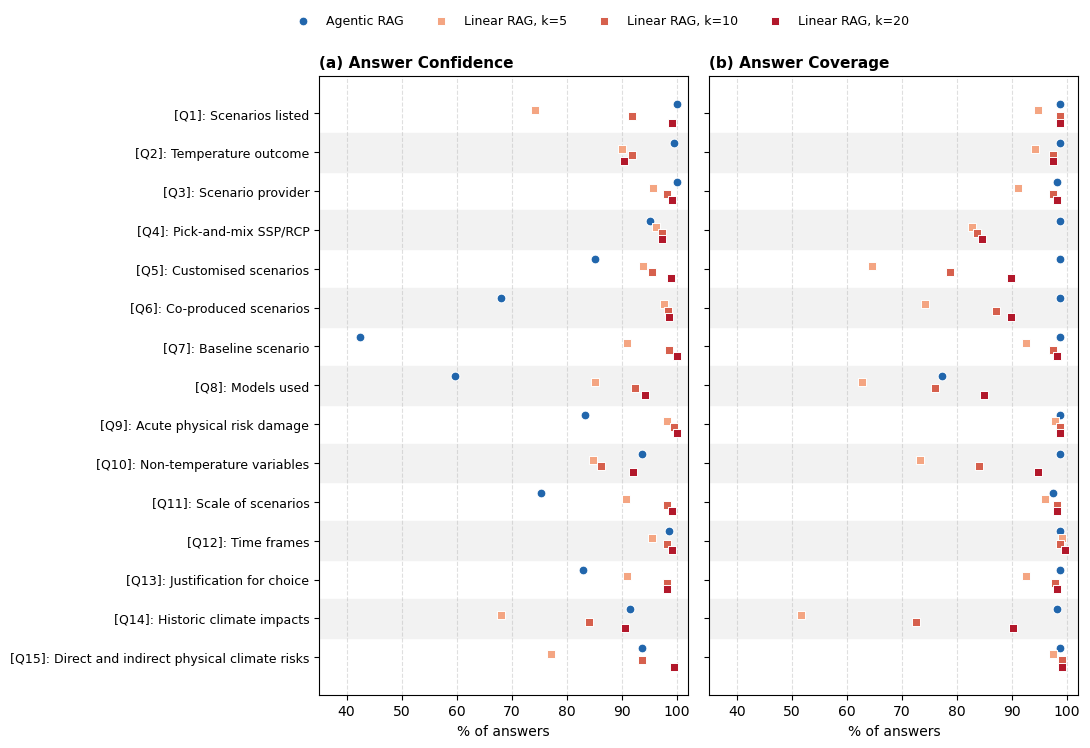

answer confidence                     answer coverage               \
config           agentic    k10    k20    k5         agentic   k10    k20   
q_id                                                                        
1                  100.0   92.0   99.0  74.0            99.0  99.0   99.0   
2                  100.0   92.0   90.0  90.0            99.0  97.0   97.0   
3                  100.0   98.0   99.0  96.0            98.0  97.0   98.0   
4                   95.0   97.0   97.0  96.0            99.0  84.0   84.0   
5                   85.0   95.0   99.0  94.0            99.0  79.0   90.0   
6                   68.0   98.0   99.0  98.0            99.0  87.0   90.0   
7                   42.0   99.0  100.0  91.0            99.0  97.0   98.0   
8                   60.0   92.0   94.0  85.0            77.0  76.0   85.0   
9                   83.0  100.0  100.0  98.0            99.0  99.0   99.0   
10                  94.0   86.0   92.0  85.0            99.0  84.0   95.0   
11                  75.0   98.0   99.0  91.0            97.0  98.0   98.0   
12                  99.0   98.0   99.0  96.0            99.0  99.0  100.0   
13                  83.0   98.0   98.0  91.0            99.0  98.0   98.0   
14                  91.0   84.0   91.0  68.0            98.0  72.0   90.0   
15                  94.0   94.0  100.0  77.0            99.0  99.0   99.0   

              
config    k5  
q_id          
1       95.0  
2       94.0  
3       91.0  
4       83.0  
5       64.0  
6       74.0  
7       92.0  
8       63.0  
9       98.0  
10      73.0  
11      96.0  
12      99.0  
13      92.0  
14      52.0  
15      97.0

In [24]:
# Figure: completeness and confidence per question, agentic vs fixed-K linear RAG
import matplotlib.pyplot as plt

Q_LABEL = {1: 'Scenarios listed', 2: 'Temperature outcome', 3: 'Scenario provider', 4: 'Pick-and-mix SSP/RCP',
           5: 'Customised scenarios', 6: 'Co-produced scenarios', 7: 'Baseline scenario', 8: 'Models used',
           9: 'Acute physical risk damage', 10: 'Non-temperature variables', 11: 'Scale of scenarios',
           12: 'Time frames', 13: 'Justification for choice', 14: 'Historic climate impacts',
           15: 'Direct and indirect physical climate risks'}
OFFSET = {'agentic': -0.24, 'k5': -0.08, 'k10': 0.08, 'k20': 0.24}   # small vertical offsets so no dot hides another
SERIES = {'agentic': ('Agentic RAG', '#2166AC', 'o'),
          'k5':  ('Linear RAG, k=5',  '#F4A582', 's'),
          'k10': ('Linear RAG, k=10', '#D6604D', 's'),
          'k20': ('Linear RAG, k=20', '#B2182B', 's')}

found_by_q = full.pivot_table(index='q_id', columns='config', values='found', aggfunc='mean')
high_by_q = found.assign(high=found.confidence.eq('high')).pivot_table(
    index='q_id', columns='config', values='high', aggfunc='mean')
order = list(range(1, 16))
labels = [f'[Q{q}]: {Q_LABEL[q]}' for q in range(1, 16)]
y = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(11, 7.5), sharey=True)
for ax, data, title in ((axes[0], high_by_q, '(a) Answer Confidence'),
                        (axes[1], found_by_q, '(b) Answer Coverage')):
    vals = data.reindex(order)
    for i in y[1::2]:
        ax.axhspan(i - 0.5, i + 0.5, color='#F2F2F2', zorder=0)   # light banding to group each question's dots
    for config, (name, color, marker) in SERIES.items():
        ax.scatter(vals[config] * 100, y + OFFSET[config], s=40, color=color, marker=marker, label=name,
                   edgecolor='white', linewidth=0.7, zorder=3)
    ax.set_title(title, fontsize=11, fontweight='bold', loc='left')
    ax.set_xlabel('% of answers')
    ax.set_xlim(35, 102)
    ax.xaxis.grid(True, linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)

axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=9)
axes[0].invert_yaxis()
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc='upper center', ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.55, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.95))   # leave room at the top for the legend
plt.savefig(PLOT_OUTPUT_DIR / 'FigS_full_sample_completeness_confidence.png', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()
pd.concat({'answer confidence': high_by_q.reindex(order), 'answer coverage': found_by_q.reindex(order)},
          axis=1).mul(100).round(0)